In [192]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tslearn.metrics import dtw
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.arima.model import ARIMA
from scipy.signal import periodogram

## (a) Data preparation

In [193]:
df = pd.read_csv("GlobalLandTemperaturesByCountry.csv", parse_dates=['dt'])
print(df.shape)
df.head()

(577462, 4)


,dt,AverageTemperature,AverageTemperatureUncertainty,Country
0,1743-11-01,4.384,2.294,Åland
1,1743-12-01,NaN,NaN,Åland
2,1744-01-01,NaN,NaN,Åland
3,1744-02-01,NaN,NaN,Åland
4,1744-03-01,NaN,NaN,Åland


In [194]:
countries = ['Norway', 'Finland', 'Singapore', 'Cambodia']

temps = (df[df['Country'].isin(countries)]
         .pivot(index='dt', columns='Country', values='AverageTemperature')
         .sort_index()
         .loc['1900':'2012'])

print("Missing values per country (1900-2012):")
print(temps.isna().sum())
temps.head()

Missing values per country (1900-2012):
Country
Cambodia     0
Finland      0
Norway       0
Singapore    0
dtype: int64


Country,Cambodia,Finland,Norway,Singapore
dt,,,,
1900-01-01,24.389,-11.824,-8.844,25.764
1900-02-01,25.802,-15.801,-13.377,26.385
1900-03-01,27.561,-7.537,-6.757,26.838
1900-04-01,29.368,-1.937,-3.225,26.947
1900-05-01,28.296,4.401,1.874,27.363


 The full series contain missing values, mostly in the 18th and 19th century and in the last month (September 2013). By restricting all four countries to the common period 1900–2012, every series is complete (1,356 months, no missing values), so no imputation is needed. As a safeguard, any isolated gaps would be filled with `interpolate()`.

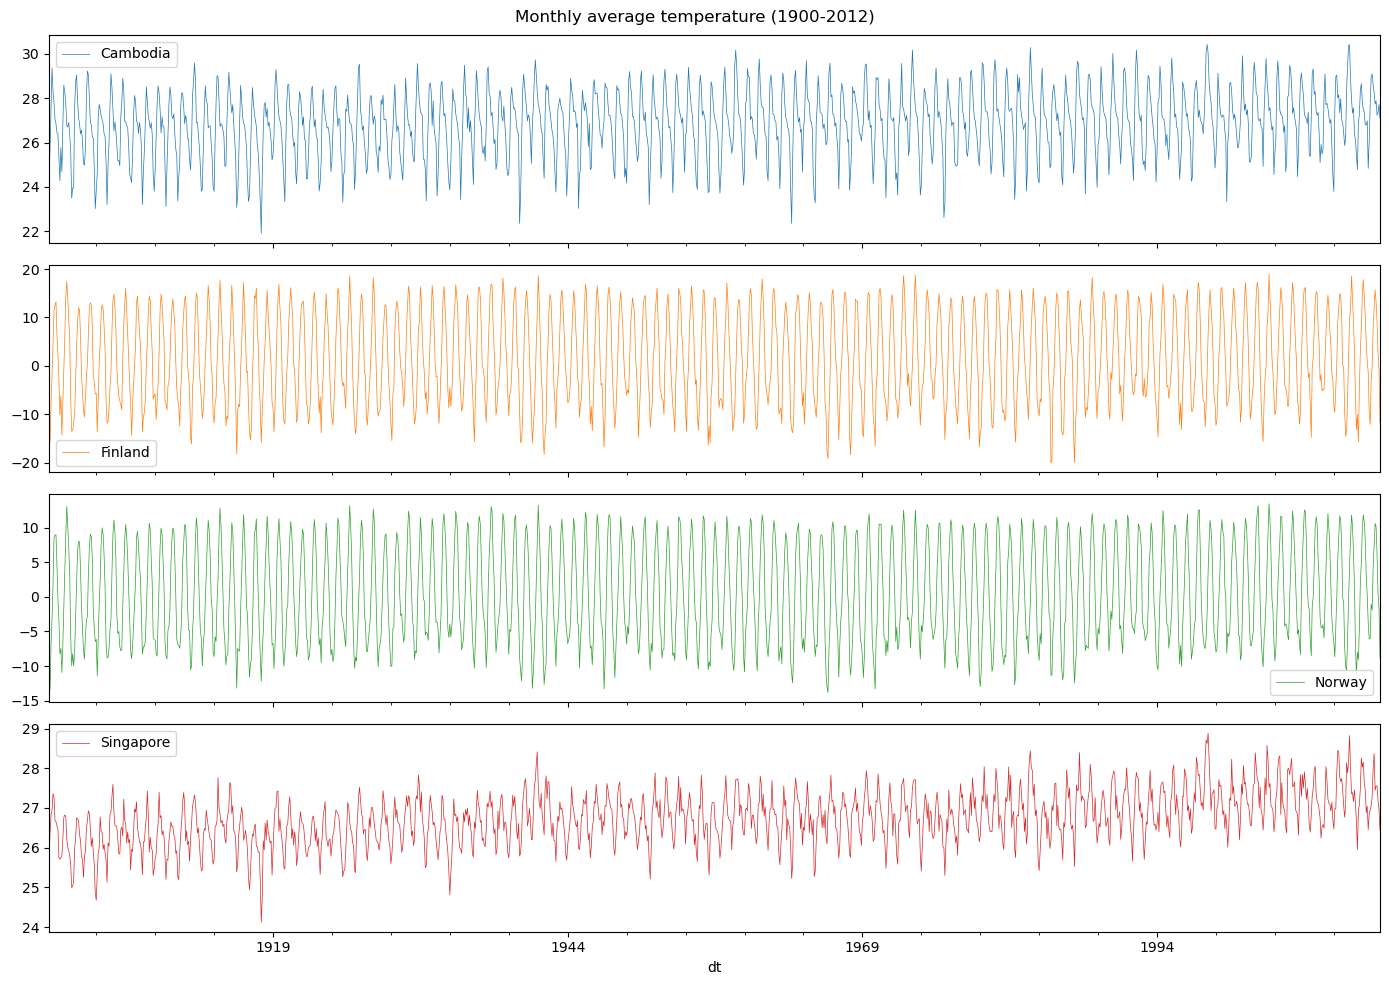

In [195]:
temps = temps.interpolate()   # no effect kept as a safeguard

temps.plot(subplots=True, figsize=(14, 10), sharex=True, linewidth=0.5,
           title="Monthly average temperature (1900-2012)")
plt.tight_layout()
plt.show()

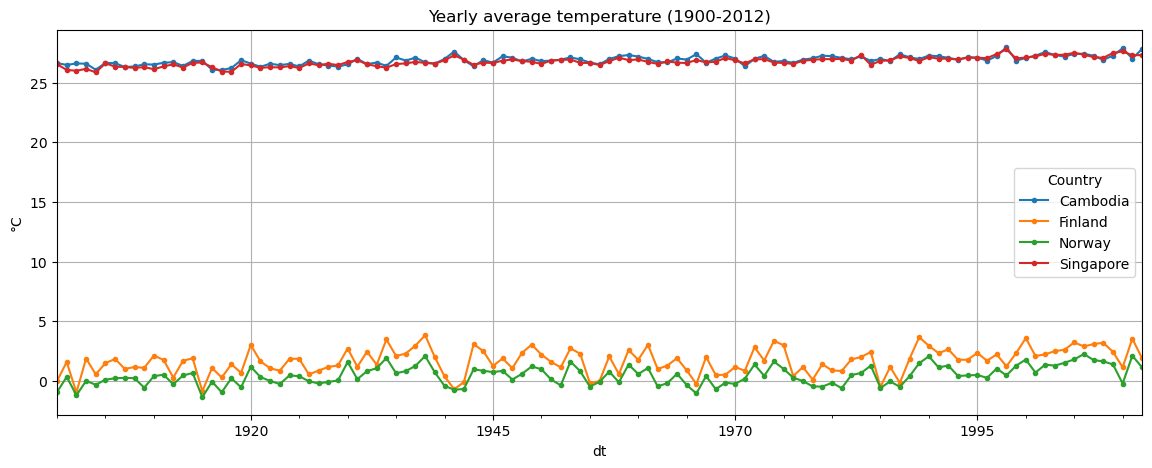

In [196]:
temps_yearly = temps.resample('YS').mean()

temps_yearly.plot(figsize=(14, 5), marker='.', title="Yearly average temperature (1900-2012)")
plt.ylabel('°C')
plt.grid(True)
plt.show()

## (b) Comparison with DTW

DTW finds the alignment between two series that minimises the total distance, allowing point *i* of one series to be matched with point *j* of the other (stretching or compressing time), and sums the differences along that path. Euclidean distance instead always compares point *i* with point *i*.

#### (i) Raw yearly data

In [197]:
def dist_matrix(data, metric):
    cols = data.columns
    M = pd.DataFrame(0.0, index=cols, columns=cols)
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            M.loc[a, b] = M.loc[b, a] = metric(data[a].values, data[b].values)
    return M.round(2)

In [198]:
dtw_raw = dist_matrix(temps_yearly, dtw)
dtw_raw

Country,Cambodia,Finland,Norway,Singapore
Country,,,,
Cambodia,0.00,268.33,280.91,1.74
Finland,268.33,0.00,8.75,266.97
Norway,280.91,8.75,0.00,279.55
Singapore,1.74,266.97,279.55,0.00


In the yearly raw data, the distance is huge between the Nordic (Norway, Finland) and tropical countries (Cambodia, Singapore), but countries with similar climates are close. Therefore, on raw data DTW simply measures how different the average temperature levels of the countries are, not the shape of the series.

#### (ii) After z-normalising each series

In [199]:
def euclidean(a, b):
    return np.linalg.norm(a - b)

def z_normalise(data):
    return (data - data.mean()) / data.std()

In [200]:
z_yearly = z_normalise(temps_yearly)

dtw_z = dist_matrix(z_yearly, dtw)
eucl_z = dist_matrix(z_yearly, euclidean)

print("DTW (z-normalised)")
display(dtw_z)
print("Euclidean (z-normalised)")
display(eucl_z)

DTW (z-normalised)


Country,Cambodia,Finland,Norway,Singapore
Country,,,,
Cambodia,0.00,6.56,6.14,4.44
Finland,6.56,0.00,4.03,6.90
Norway,6.14,4.03,0.00,6.07
Singapore,4.44,6.90,6.07,0.00


Euclidean (z-normalised)


Country,Cambodia,Finland,Norway,Singapore
Country,,,,
Cambodia,0.00,14.12,13.34,5.01
Finland,14.12,0.00,4.29,13.34
Norway,13.34,4.29,0.00,12.46
Singapore,5.01,13.34,12.46,0.00


After z-normalising, every value is relative to the series' own mean and standard deviation. This removes differences in mean level and variability, so DTW and Euclidean distance compare the shape of the series instead of the absolute temperature in each country.

#### Effect of a warping window (Sakoe–Chiba band)

In [201]:
radii = [0, 1, 2, 5, 10, 20]

rows = []
cols = z_yearly.columns
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        row = {'pair': f'{a} – {b}', 'Euclidean': euclidean(z_yearly[a].values, z_yearly[b].values)}
        for r in radii:
            row[f'r={r}'] = dtw(z_yearly[a].values, z_yearly[b].values,
                                global_constraint='sakoe_chiba', sakoe_chiba_radius=r)
        row['unconstrained'] = dtw(z_yearly[a].values, z_yearly[b].values)
        rows.append(row)

sakoe = pd.DataFrame(rows).set_index('pair').round(2)
sakoe

,Euclidean,r=0,r=1,r=2,r=5,r=10,r=20,unconstrained
pair,,,,,,,,
Cambodia – Finland,14.12,14.12,10.27,8.25,7.06,6.72,6.56,6.56
Cambodia – Norway,13.34,13.34,9.97,8.07,6.53,6.17,6.14,6.14
Cambodia – Singapore,5.01,5.01,4.75,4.58,4.44,4.44,4.44,4.44
Finland – Norway,4.29,4.29,4.05,4.03,4.03,4.03,4.03,4.03
Finland – Singapore,13.34,13.34,10.69,8.82,7.47,6.90,6.90,6.90
Norway – Singapore,12.46,12.46,10.00,8.27,6.60,6.07,6.07,6.07


On the raw yearly data DTW measures the difference in temperature level. The countries are grouped into two: Nordic and Tropical, thus the difference in temperature can be seen in the matrix between the two distinct group. After z-normalisation the level and variability are removed, so DTW compares the shape of the series. The two climate groups are still visible but the difference is much smaller. Warping in time is not really meaningful here because the series are measured in the same calendar years, and a warm or cold year occur in the same year everywhere. Hence, the euclidean distance is the one that we prefer to use. With r=0, no warping is allowed and DTW equals to euclidean exactly. As r grows, the distances between the climate groups shrink much faster than the distances between them.

## (c) Stationarity

In [202]:
versions = {
    'original': temps,
    'diff(1)':  temps.diff().dropna(),
    'diff(12)': temps.diff(12).dropna(),
}

rows = []
for name, data in versions.items():
    for country in data.columns:
        stat, pvalue, *_ = adfuller(data[country])
        rows.append({'Country': country, 'Series': name,
                     'ADF stat': round(stat, 3), 'p-value': round(pvalue, 4),
                     'Stationary (1%)': pvalue < 0.01})

adf_results = pd.DataFrame(rows)
adf_results

,Country,Series,ADF stat,p-value,Stationary (1%)
0,Cambodia,original,-3.767,0.0033,True
1,Finland,original,-5.180,0.0000,True
2,Norway,original,-4.107,0.0009,True
3,Singapore,original,-2.602,0.0925,False
4,Cambodia,diff(1),-12.481,0.0000,True
5,Finland,diff(1),-14.519,0.0000,True
6,Norway,diff(1),-14.671,0.0000,True
7,Singapore,diff(1),-11.609,0.0000,True
8,Cambodia,diff(12),-13.665,0.0000,True
9,Finland,diff(12),-12.575,0.0000,True


In [203]:
adf_results.pivot(index='Country', columns='Series', values='p-value')[list(versions)]

Series,original,diff(1),diff(12)
Country,,,
Cambodia,0.0033,0.0,0.0
Finland,0.0000,0.0,0.0
Norway,0.0009,0.0,0.0
Singapore,0.0925,0.0,0.0


The null hypothesis of the ADF test is that the series is non-stationary, so p < 0.01 means we reject non-stationarity at the 1% level. After differencing, all four series have p ≈ 0. And after seasonal differencing (lag 12), all four series again have p ≈ 0. Subtracting the same month of the previous year removes the seasonal cycle.

## (d) Trend and seasonality

#### (i) Differencing

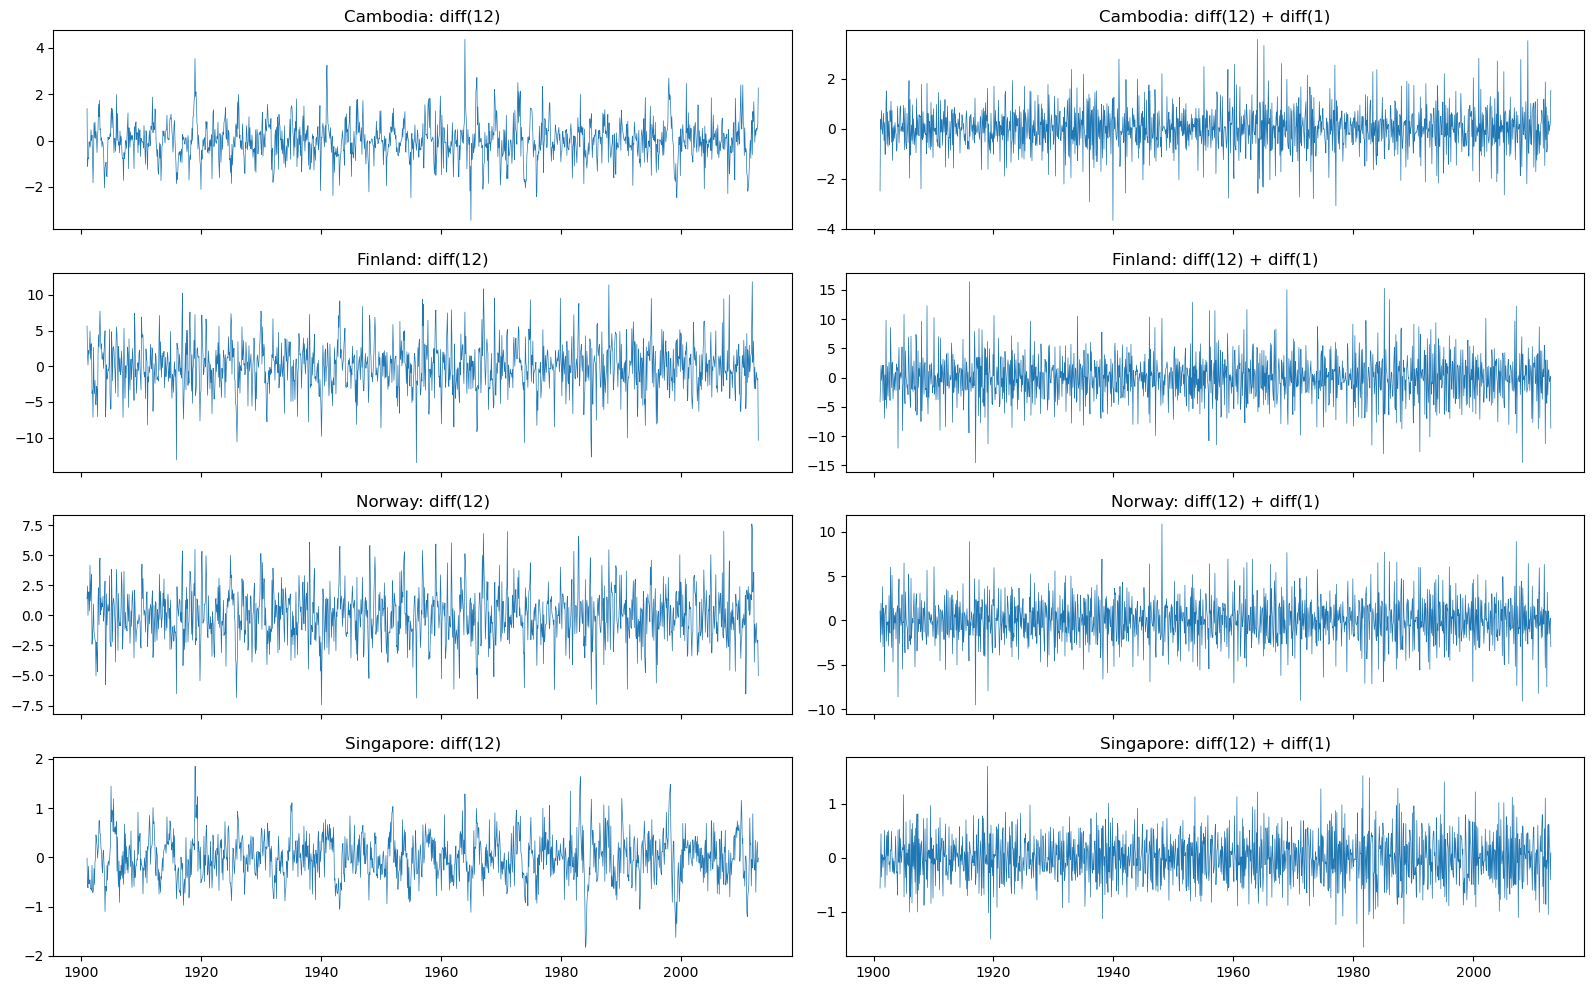

In [204]:
seasonal_diffed = temps.diff(12).dropna()
fully_diffed = temps.diff(12).diff(1).dropna()

fig, axes = plt.subplots(4, 2, figsize=(16, 10), sharex=True)
for row, c in zip(axes, temps.columns):
    row[0].plot(seasonal_diffed[c], linewidth=0.5)
    row[0].set_title(f'{c}: diff(12)')
    row[1].plot(fully_diffed[c], linewidth=0.5)
    row[1].set_title(f'{c}: diff(12) + diff(1)')
plt.tight_layout()
plt.show()

#### (ii) Classical decomposition and (iii) STL

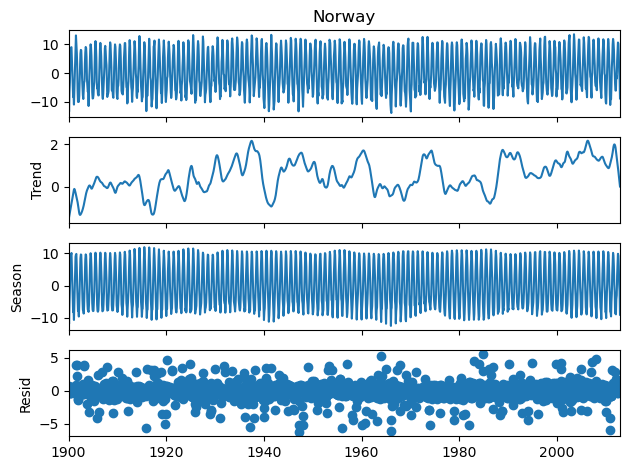

In [205]:
res_cl = {c: seasonal_decompose(temps[c], model='additive', period=12) for c in temps.columns}
res_stl = {c: STL(temps[c], period=12, robust=True).fit() for c in temps.columns}

res_stl['Norway'].plot()
plt.show()

#### Seasonal component: classical vs STL

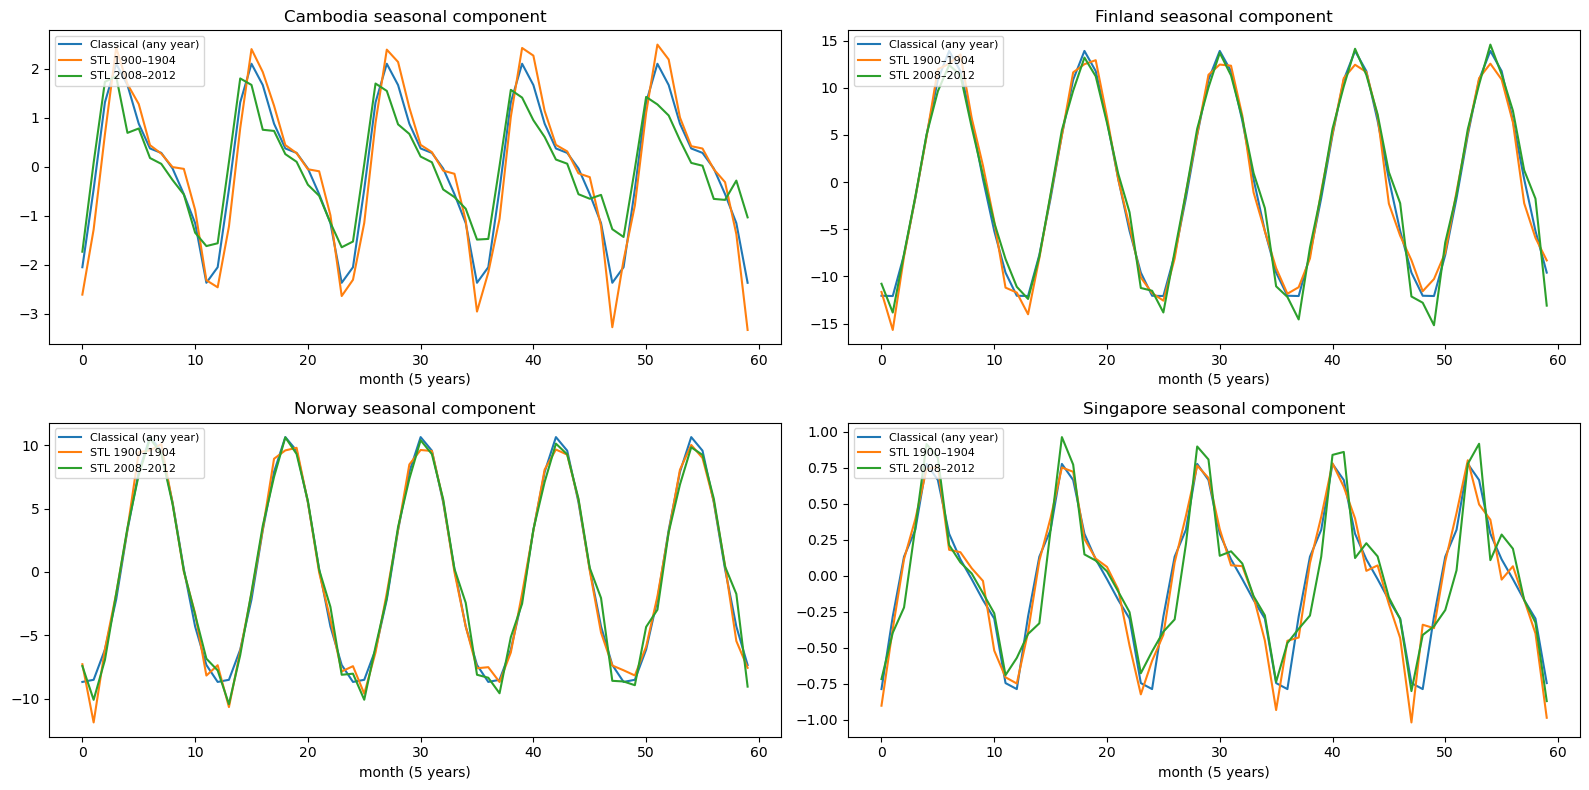

In [206]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, c in zip(axes.flat, temps.columns):
    series = {
        'Classical (any year)': res_cl[c].seasonal.loc['1900':'1904'].values,
        'STL 1900–1904':        res_stl[c].seasonal.loc['1900':'1904'].values,
        'STL 2008–2012':        res_stl[c].seasonal.loc['2008':'2012'].values,
    }
    for label, vals in series.items():
        ax.plot(vals, label=label)
    ax.set_title(f"{c} seasonal component")
    ax.set_xlabel('month (5 years)')
    ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

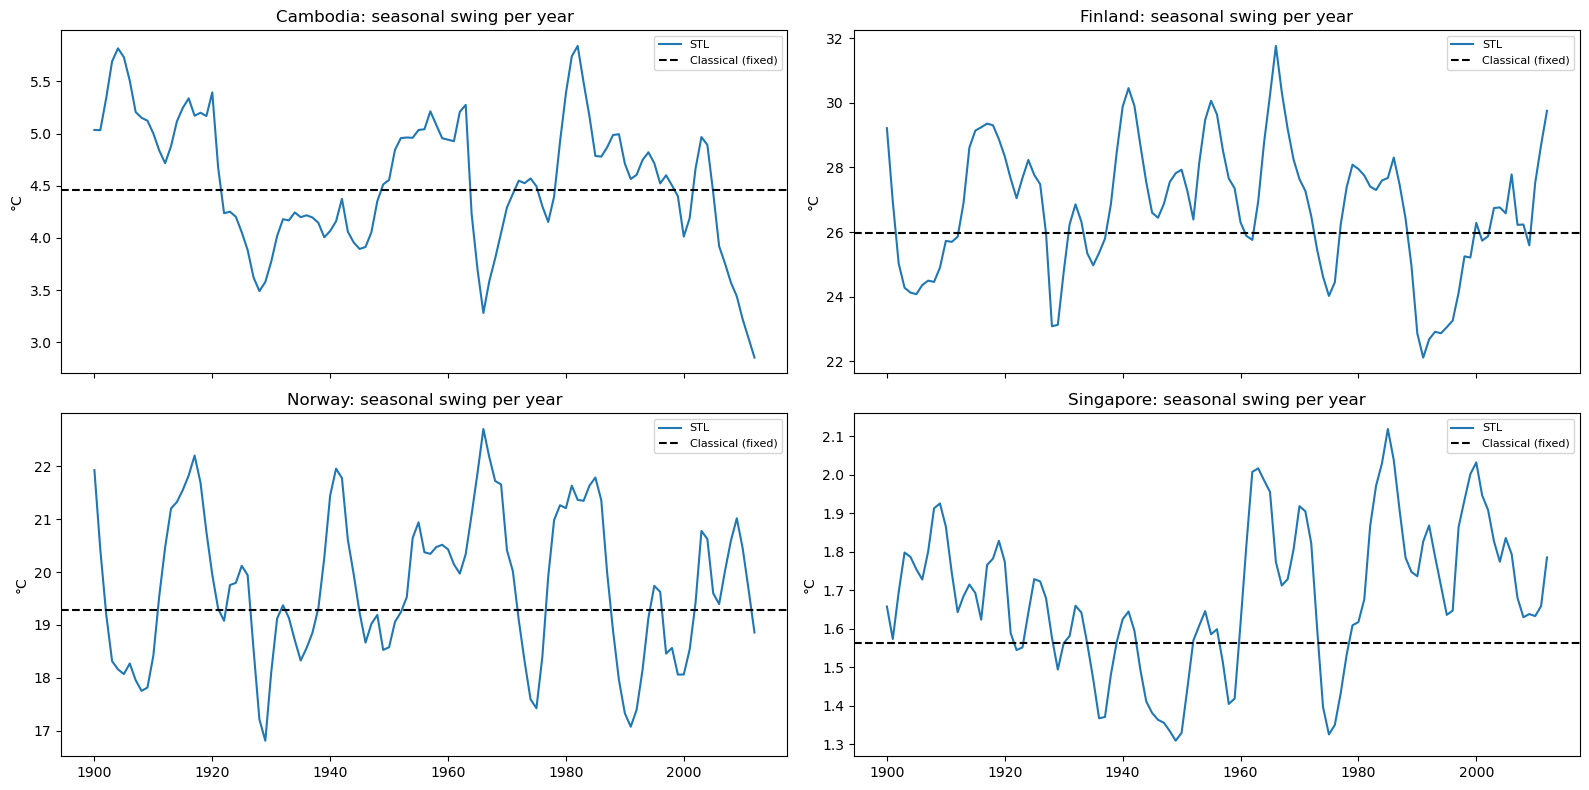

In [207]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)
for ax, c in zip(axes.flat, temps.columns):
    stl_s = res_stl[c].seasonal
    cl_s = res_cl[c].seasonal

    stl_amp = stl_s.groupby(stl_s.index.year).agg(lambda x: x.max() - x.min())
    cl_amp = cl_s.max() - cl_s.min()

    ax.plot(stl_amp.index, stl_amp.values, label='STL')
    ax.axhline(cl_amp, color='black', linestyle='--', label='Classical (fixed)')
    ax.set_title(f'{c}: seasonal swing per year')
    ax.set_ylabel('°C')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Classical decomposition estimates one fixed seasonal pattern and repeats it identically every year, so by construction it cannot show any change over time (flat line in the plot). STL re-estimates the seasonal component locally and lets it evolve: for every country the seasonal swing varies over time. In Finland and Norway the swing was largest in 1940–1979 (colder winters) and decreased after 1980 as winters became milder, while summers stayed stable. In Cambodia and Singapore the swing fluctuates around a stable level (≈4.4°C and ≈1.7°C). So the seasonal pattern is broadly stable in shape, but its strength changes over time, mainly through the winter months.

The second graph generated to picture how the seasonal pattern change over time per year, by subtracting the maximum change and minimum change in the year.


#### Trend components

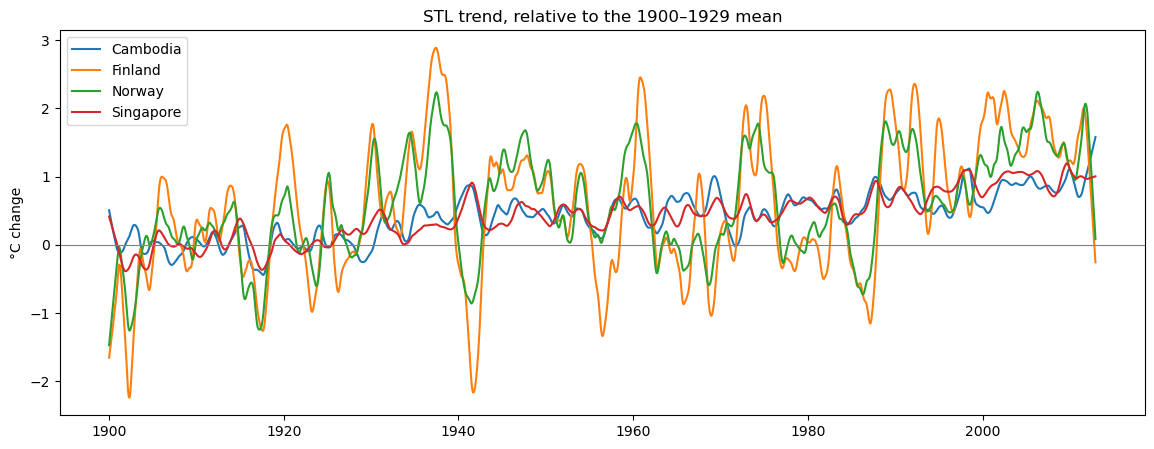

In [208]:
trends = pd.DataFrame({c: res_stl[c].trend for c in temps.columns})

fig, ax = plt.subplots(figsize=(14, 5))
for c in trends.columns:
    ax.plot(trends[c] - trends[c].loc['1900':'1929'].mean(), label=c)
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_title('STL trend, relative to the 1900–1929 mean')
ax.set_ylabel('°C change')
ax.legend()
plt.show()

The trends are plotted relative to each country's 1900–1929 mean, so all four fit in one figure despite their different temperature levels. All four series show a positive long-term trend between 1900 and 2012. The tropical countries warm gradually and steadily, whereas the Nordic trend is more irregular with high variability. The nordic countries is dominated with its seasonality as temperatures swing between summer and winter as the STL above shown.
This pattern is consistent with climate warming, with the largest increase in the nordic countries.

#### DTW on trend and remainder components

In [209]:
remainders = pd.DataFrame({c: res_stl[c].resid for c in temps.columns})

trends_yearly = trends.resample('YS').mean()
remainders_yearly = remainders.resample('YS').mean()

print("DTW on z-normalised trend")
display(dist_matrix(z_normalise(trends_yearly), dtw))
print("DTW on z-normalised remainder")
display(dist_matrix(z_normalise(remainders_yearly), dtw))
print("DTW on z-normalised yearly data")
display(dtw_z)

DTW on z-normalised trend


,Cambodia,Finland,Norway,Singapore
Cambodia,0.00,6.24,5.55,3.42
Finland,6.24,0.00,3.78,6.35
Norway,5.55,3.78,0.00,5.82
Singapore,3.42,6.35,5.82,0.00


DTW on z-normalised remainder


,Cambodia,Finland,Norway,Singapore
Cambodia,0.00,8.02,8.03,7.46
Finland,8.02,0.00,6.15,8.14
Norway,8.03,6.15,0.00,8.27
Singapore,7.46,8.14,8.27,0.00


DTW on z-normalised yearly data


Country,Cambodia,Finland,Norway,Singapore
Country,,,,
Cambodia,0.00,6.56,6.14,4.44
Finland,6.56,0.00,4.03,6.90
Norway,6.14,4.03,0.00,6.07
Singapore,4.44,6.90,6.07,0.00


On z-normalized trend, we can still see a quite separation between the two climate groups, similar to what we found in part B. Therefore, the DTW on z-normalised yearly data comes mainly from the shared long-run trend between the two groups.

The pairwise DTW on remainder is almost the same for every pair. The remainder, or noise, itself is the product once trend and seasonality are removed, and that noise is mostly unrelated between countries. Thus, DTW cannot tell if the group (nordic vs tropical) still exist



## (e) Forecast comparison

In [210]:
##Singapore
temps_sgp = temps['Singapore']
temps_sgp.head()

dt
1900-01-01    25.764
1900-02-01    26.385
1900-03-01    26.838
1900-04-01    26.947
1900-05-01    27.363
Name: Singapore, dtype: float64

In [211]:
train, test = temps_sgp[:-24], temps_sgp[-24:]
test.head()


dt
2011-01-01    25.957
2011-02-01    26.936
2011-03-01    27.083
2011-04-01    27.507
2011-05-01    28.259
Name: Singapore, dtype: float64

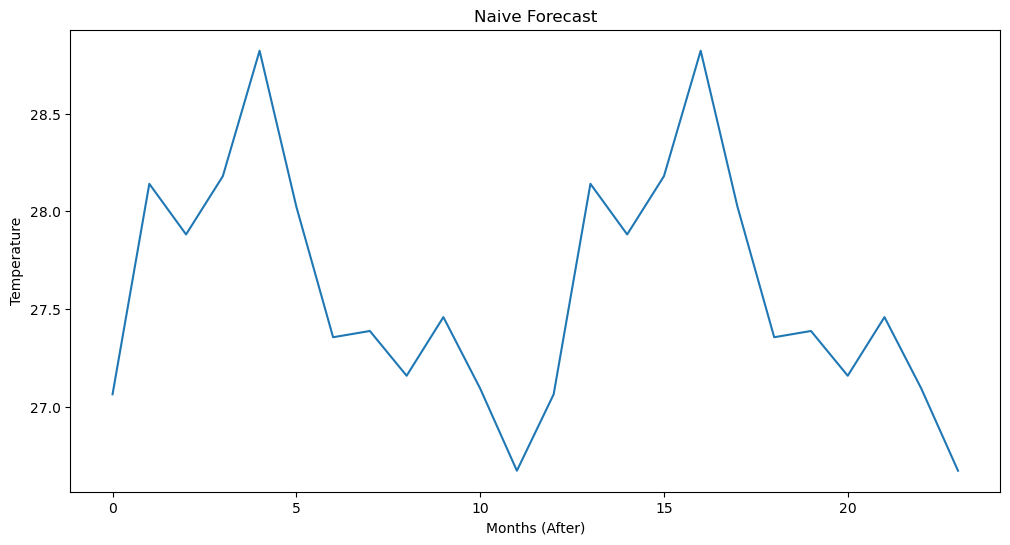

In [212]:
fc_naive = np.tile(train[-12:].values, 2)
plt.figure(figsize=(12, 6))
plt.title("Naive Forecast")
plt.ylabel("Temperature")
plt.xlabel("Months (After)")
plt.plot(fc_naive)
plt.show()

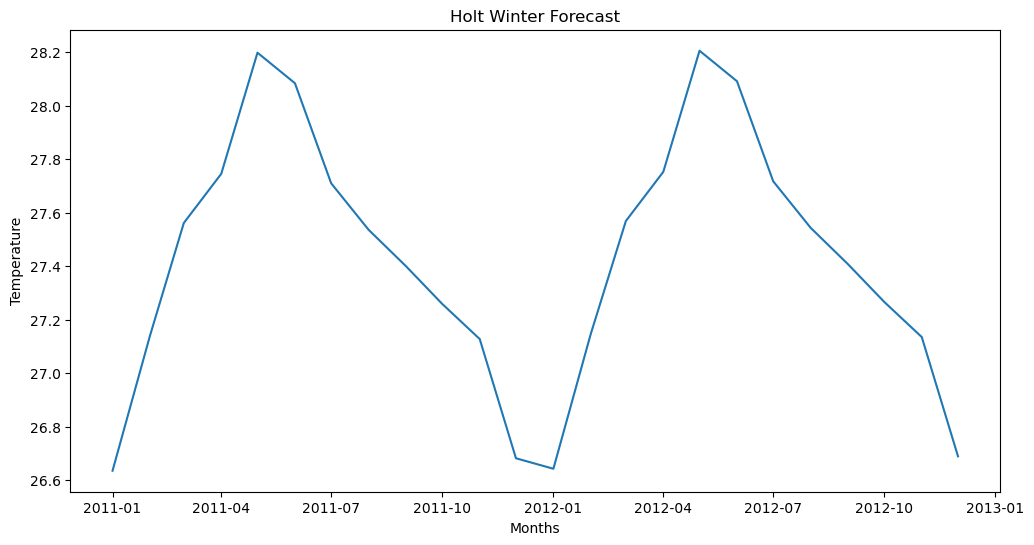

In [213]:
holt = ExponentialSmoothing(train, trend='add', seasonal='add', freq='MS', seasonal_periods=12).fit()
fc_holt = holt.forecast(24)

plt.figure(figsize=(12,6))
plt.title("Holt Winter Forecast")
plt.ylabel("Temperature")
plt.xlabel("Months")
plt.plot(fc_holt)
plt.show()

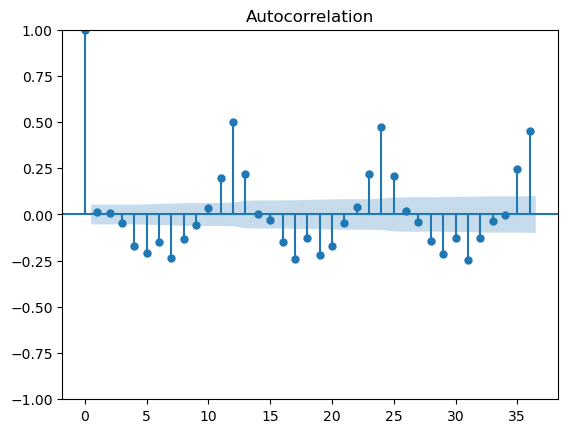

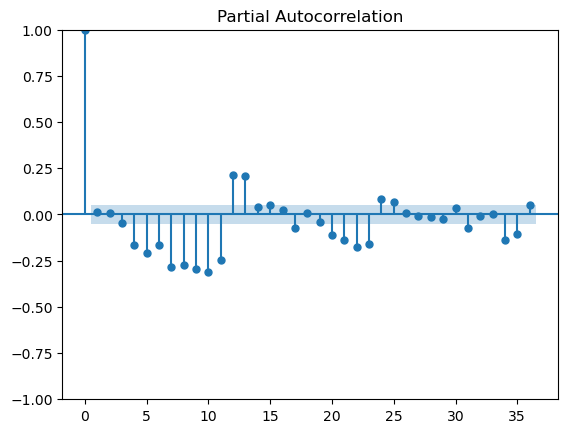

In [214]:
plot_acf(train.diff().dropna(), lags=36)
plot_pacf(train.diff().dropna(), lags=36)
plt.show()

In [215]:
ar = ARIMA(train, order=(1,1,1), freq='MS').fit()
fc_ar = ar.forecast(24)

/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


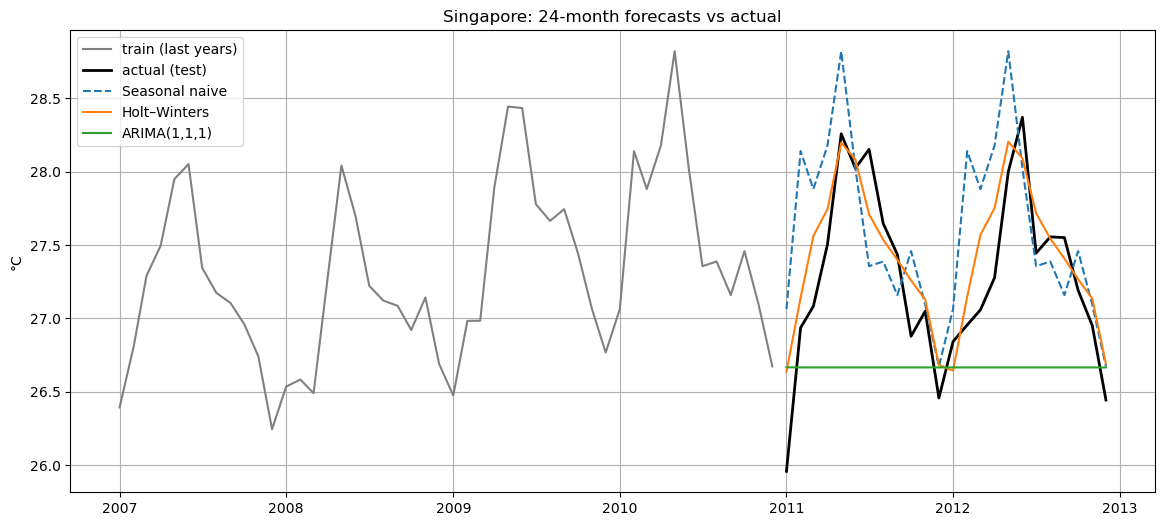

In [216]:
plt.figure(figsize=(14, 6))
plt.plot(train.loc['2007':], color='grey', label='train (last years)')
plt.plot(test, color='black', linewidth=2, label='actual (test)')
plt.plot(test.index, fc_naive, '--', label='Seasonal naive')
plt.plot(test.index, fc_holt, label='Holt–Winters')
plt.plot(test.index, fc_ar, label='ARIMA(1,1,1)')
plt.title('Singapore: 24-month forecasts vs actual')
plt.ylabel('°C'); 
plt.legend(); 
plt.grid(True); 
plt.show()


In [217]:
forecasting_models = {
    'Naive' : fc_naive,
    'Holt-Winters': fc_holt,
    'ARIMA': fc_ar
}

results = pd.DataFrame([
    {'Model' : name,
     'RMSE' : np.sqrt(mean_squared_error(test, model)),
     'MAE' : mean_absolute_error(test, model)
     } for name,model in forecasting_models.items()
])

results

,Model,RMSE,MAE
0,Naive,0.623523,0.504792
1,Holt-Winters,0.295044,0.241510
2,ARIMA,0.860703,0.722375


The Holt-Winters is additive bacause the Singapore's seasonal swing is small and roughly constant and is not growing. For the ARIMA models, p=1 and q=1 is chosen since the ACF and PACF shows no significant correlation at lag 1-3. However, larger spikes are observed at lag 12, 24, and 36 most likely because of the seasonal behavior. Since it is seasonal, a SARIMA model is more appropriate to be used here as it can take account of the seasonal structure.

Based on the RMSE and MAE of every model, Holt-Winters beats the baseline (naive) model with several reasons. Holt–Winters estimates the seasonal pattern as an exponentially weighted average over many past seasons so noised/anomaly structure of past gets diluted, whereas naive solely takes the last seasonal observation, including its noise. Holt-winters also extrapolates the trend drift of the series, which is reliable here due to warming.

#### SARIMA model

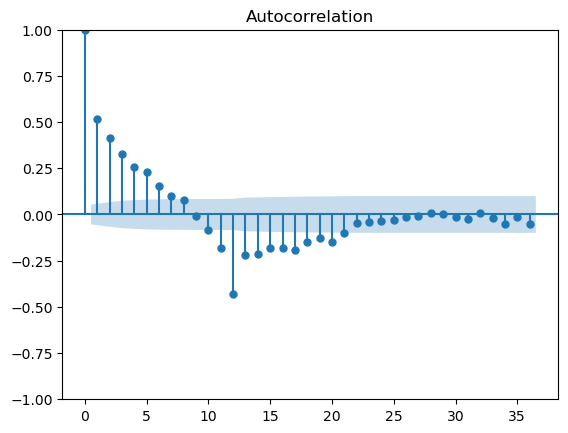

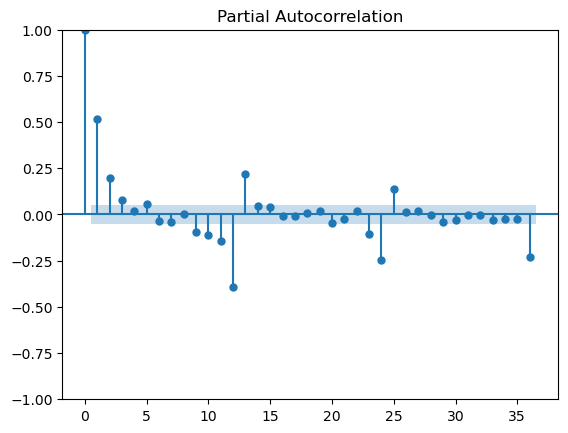

In [218]:
plot_acf(train.diff(12).dropna(), lags=36)
plot_pacf(train.diff(12).dropna(), lags=36)
plt.show()

In [219]:
sar = ARIMA(train, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit()
fc_sar = sar.forecast(24)


/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


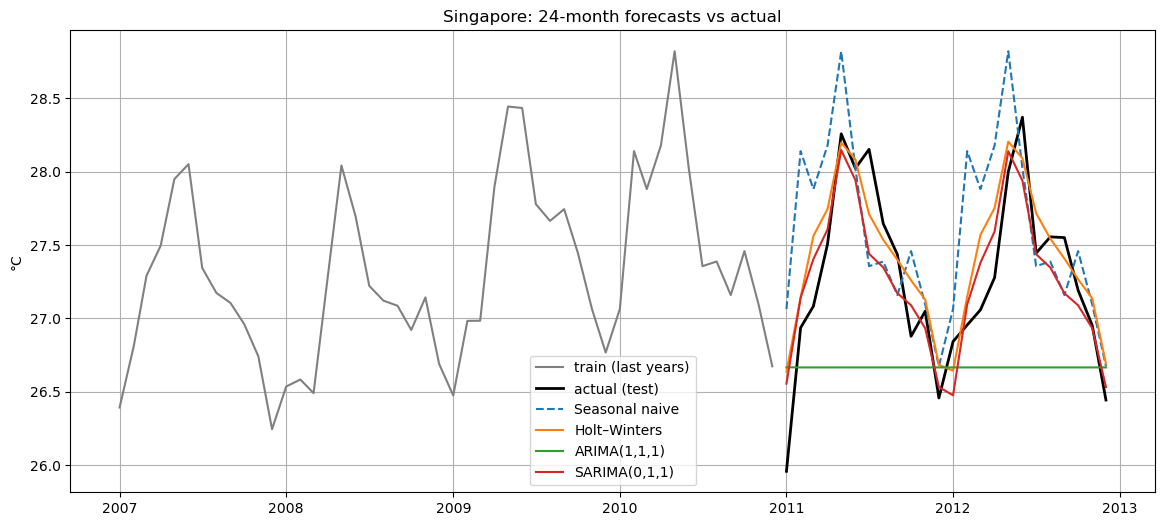

In [220]:
plt.figure(figsize=(14, 6))
plt.plot(train.loc['2007':], color='grey', label='train (last years)')
plt.plot(test, color='black', linewidth=2, label='actual (test)')
plt.plot(test.index, fc_naive, '--', label='Seasonal naive')
plt.plot(test.index, fc_holt, label='Holt–Winters')
plt.plot(test.index, fc_ar, label='ARIMA(1,1,1)')
plt.plot(test.index, fc_sar, label='SARIMA(0,1,1)')
plt.title('Singapore: 24-month forecasts vs actual')
plt.ylabel('°C'); plt.legend(); plt.grid(True); plt.show()


In [221]:
forecasting_models = {
    'Naive' : fc_naive,
    'Holt-Winters': fc_holt,
    'ARIMA': fc_ar,
    'SARIMA': fc_sar
}

results = pd.DataFrame([
    {'Model' : name,
     'RMSE' : np.sqrt(mean_squared_error(test, model)),
     'MAE' : mean_absolute_error(test, model)
     } for name,model in forecasting_models.items()
])

results

,Model,RMSE,MAE
0,Naive,0.623523,0.504792
1,Holt-Winters,0.295044,0.241510
2,ARIMA,0.860703,0.722375
3,SARIMA,0.291027,0.234014


 The difference between SARIMA and Holt–Winters is small, so for this series both are good choices. The key factor is whether the model accounts for the yearly cycle.

## (f) Multiple Seasonality

In [222]:
url = "https://archive-api.open-meteo.com/v1/archive?latitude=1.2897&longitude=103.8501&start_date=2023-09-24&end_date=2026-10-08&hourly=temperature_2m&format=csv"

In [223]:
y = pd.read_csv(url, skiprows=2, parse_dates=['time'], index_col='time').iloc[:, 0]
y

time
2023-09-24 00:00:00    24.8
2023-09-24 01:00:00    24.9
2023-09-24 02:00:00    25.0
2023-09-24 03:00:00    25.3
2023-09-24 04:00:00    26.4
                       ... 
2026-10-08 19:00:00    26.8
2026-10-08 20:00:00    26.4
2026-10-08 21:00:00    26.4
2026-10-08 22:00:00    26.3
2026-10-08 23:00:00    26.3
Name: temperature_2m (°C), Length: 26664, dtype: float64

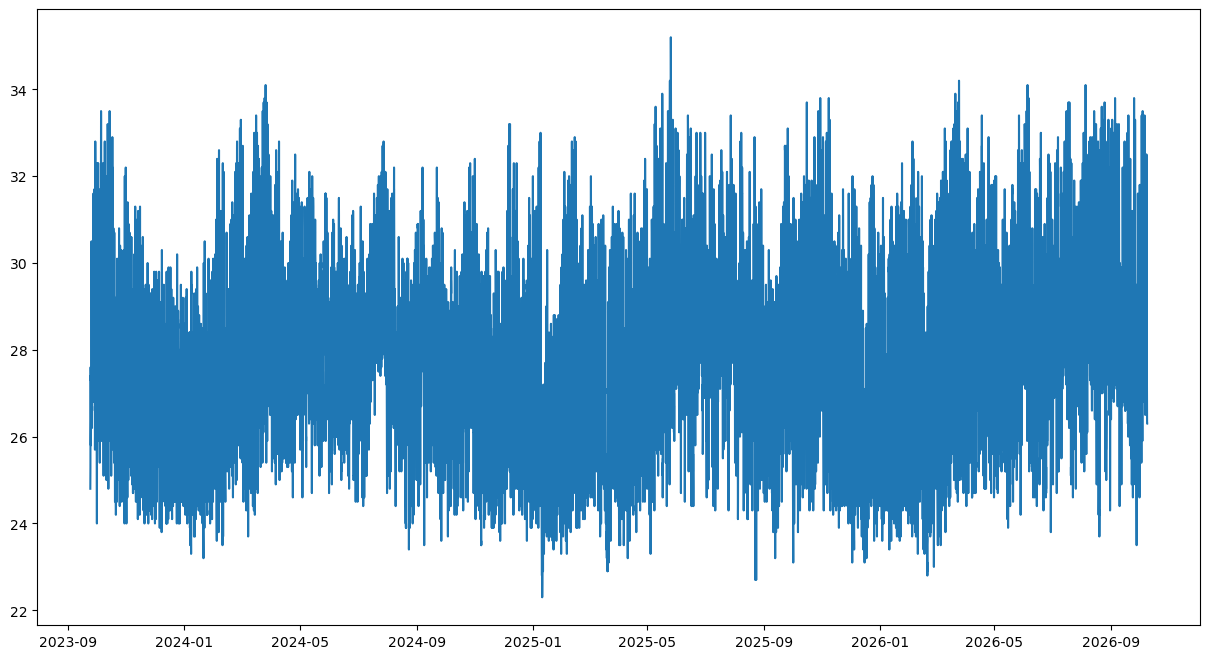

In [224]:
plt.figure(figsize=(15, 8))
plt.plot(y)
plt.show()

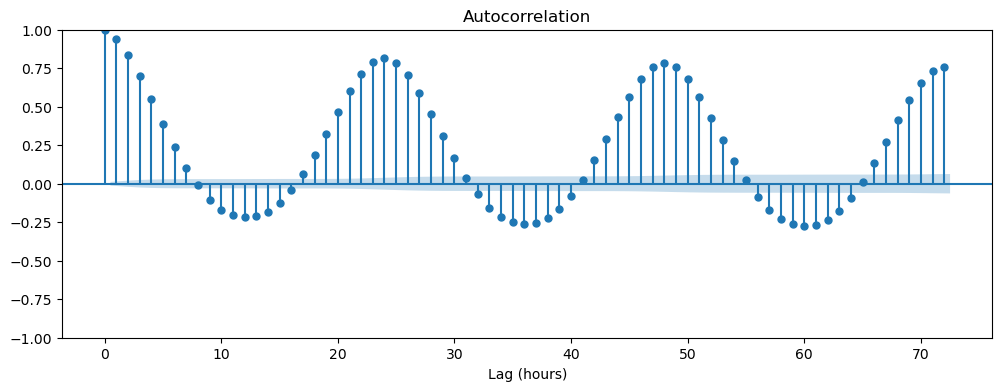

In [225]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(y, lags=24*3, ax=ax)

ax.set_xlabel('Lag (hours)')
plt.show()


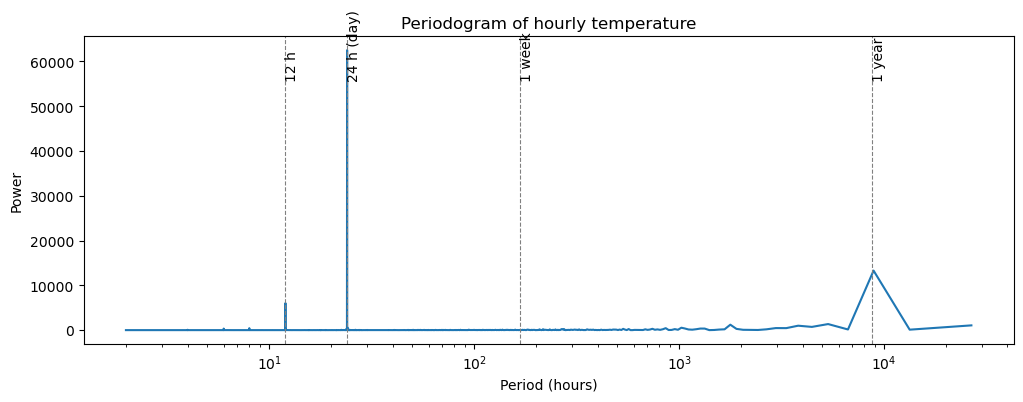

In [226]:
f, p = periodogram(y.values)
mask = f > 0
period = 1/f[mask]
plt.figure(figsize=(12, 4))
plt.semilogx(period, p[mask])
for h, name in [(12, '12 h'), (24, '24 h (day)'), (24*7, '1 week'), (24*365, '1 year')]:
    plt.axvline(h, color='grey', linestyle='--', linewidth=0.8)
    plt.text(h, p[mask].max() * 0.9, name, rotation=90)
plt.xlabel('Period (hours)'); plt.ylabel('Power'); plt.title('Periodogram of hourly temperature')
plt.show()

With the ACF and periodogram, we can conclude that the daily (lag = 24) period has the highest power as well as yearly (h = 24 * 365) period.

In [227]:
res = MSTL(
    y,
    periods=[24, 24*365],
    iterate=1,
    stl_kwargs={
        "seasonal_deg": 0,
        "trend_jump": 50, # skip losses calculation and uses interpolation (faster)
        "low_pass_jump": 100,
    },
).fit()
res1 = STL(y, period=24).fit()

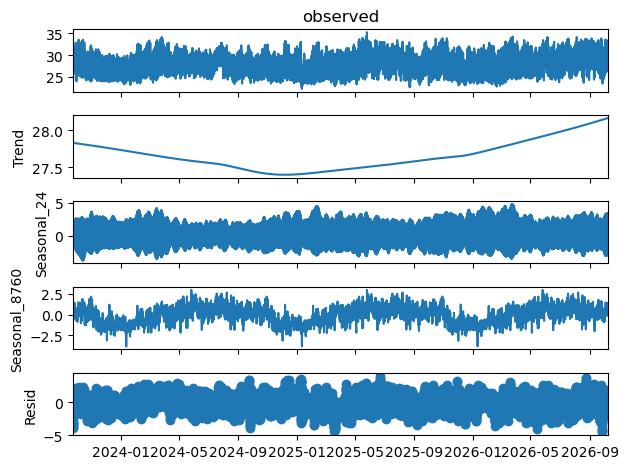

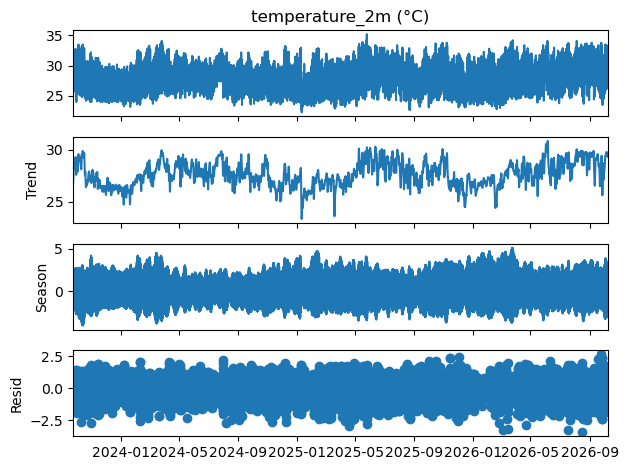

In [228]:
res.plot()
plt.show()
res1.plot()
plt.show()

The observed trend in STL and MSTL is different because in STL with period=24, it only knows about the daily cycle but the data also contains a yearly cycle. That yearly variation is absorbed by the trend thus it rises and falls with the seasons. Whereas MSTL has a seperate yearly component, so the yearly cycle is taken out and the trend no longer contains it.

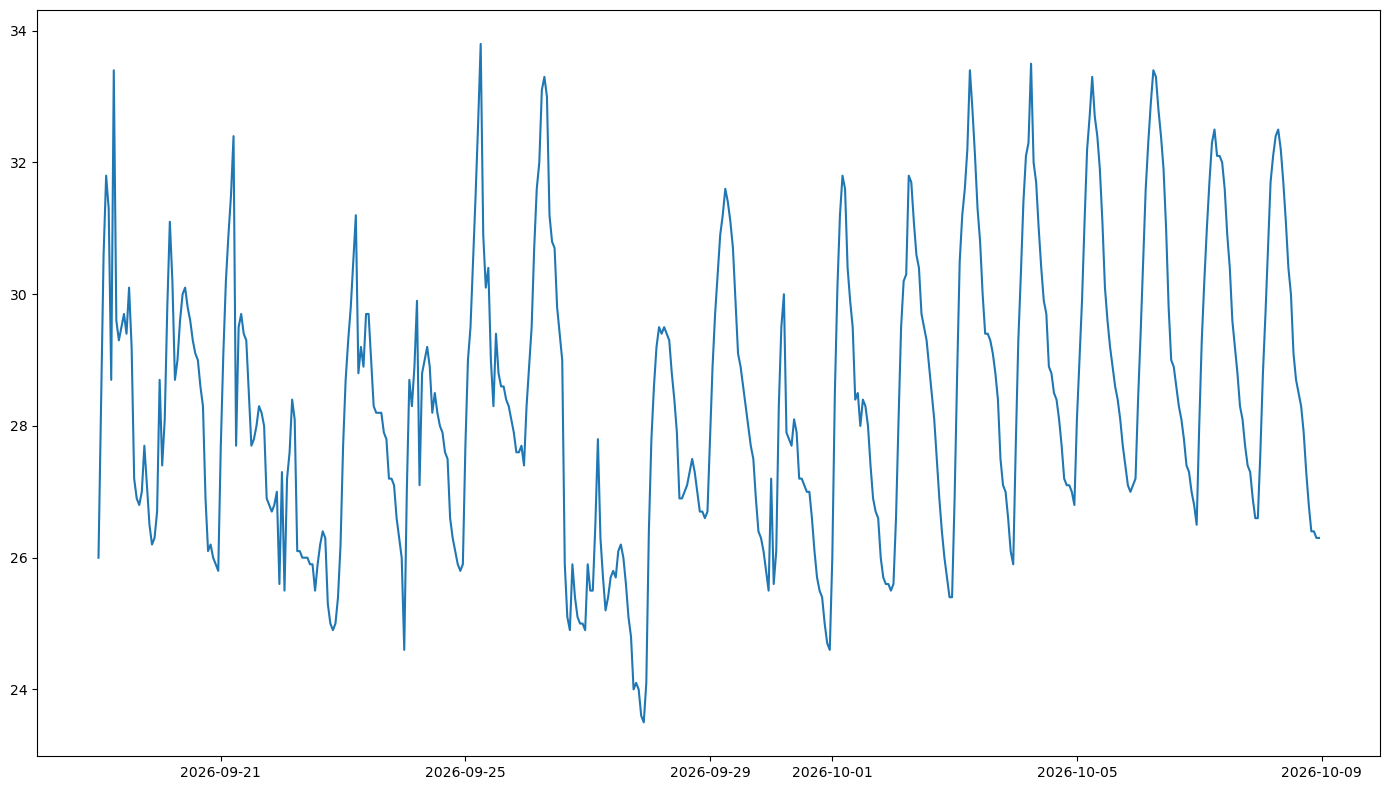

In [229]:
plt.figure(figsize=(14, 8))
plt.plot(y.iloc[-480:])
plt.tight_layout()
plt.show()

In [230]:
idx = 7 * 24
train, test = y[:-idx], y[-idx:]


In [231]:
fc_naive = np.tile(train[-24:].values, reps=7)


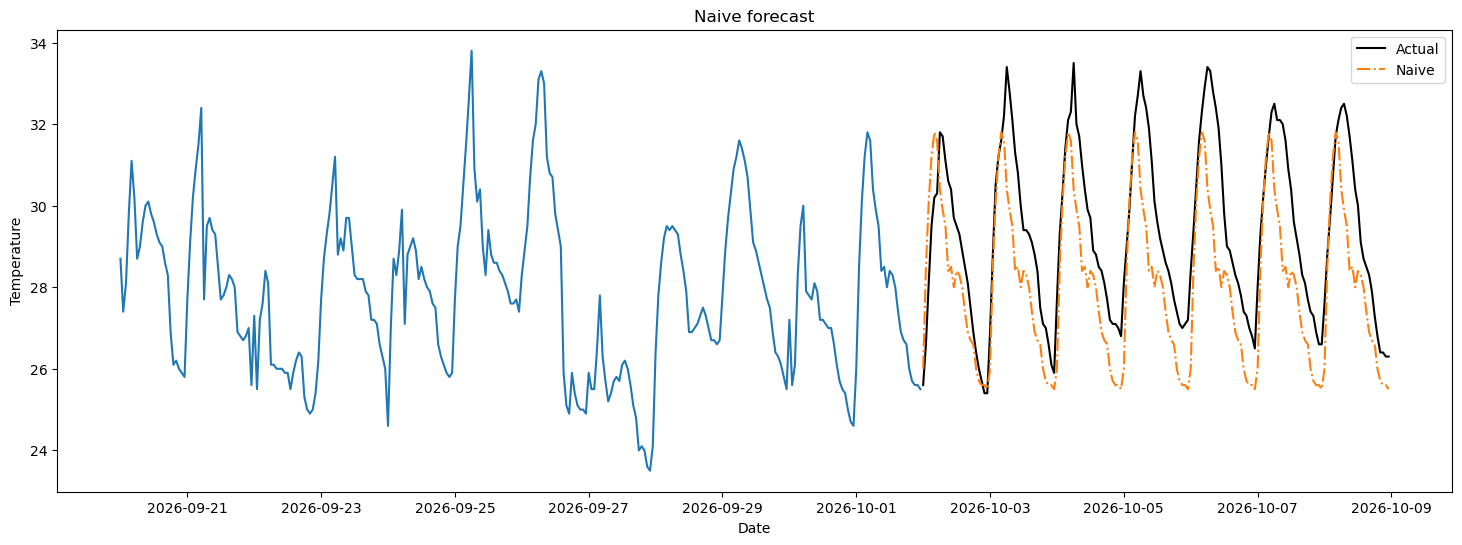

In [232]:
plt.figure(figsize=(18, 6))
plt.plot(train.loc['2026-09-20':])
plt.plot(test, c='black', label='Actual')
plt.plot(test.index, fc_naive, label='Naive', linestyle='-.')
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.title("Naive forecast")
plt.legend()
plt.show()

In [233]:
res_tr = MSTL(train, periods=(24, 24*365),
              stl_kwargs={'seasonal_jump': 24, 'trend_jump': 24, 'low_pass_jump': 24}).fit()
seas = res_tr.seasonal


In [234]:
y_adj = train - seas.sum(axis=1)
fc_adj = ExponentialSmoothing(y_adj, trend='add').fit().forecast(idx)

/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


In [235]:
daily = np.tile(seas['seasonal_24'][-24:].values, reps=7)
yearly = seas['seasonal_8760'][-idx:].values

fc_mstl = fc_adj.values + daily + yearly

Seasonal naive  RMSE 1.66  MAE 1.40
MSTL            RMSE 2.31  MAE 1.83


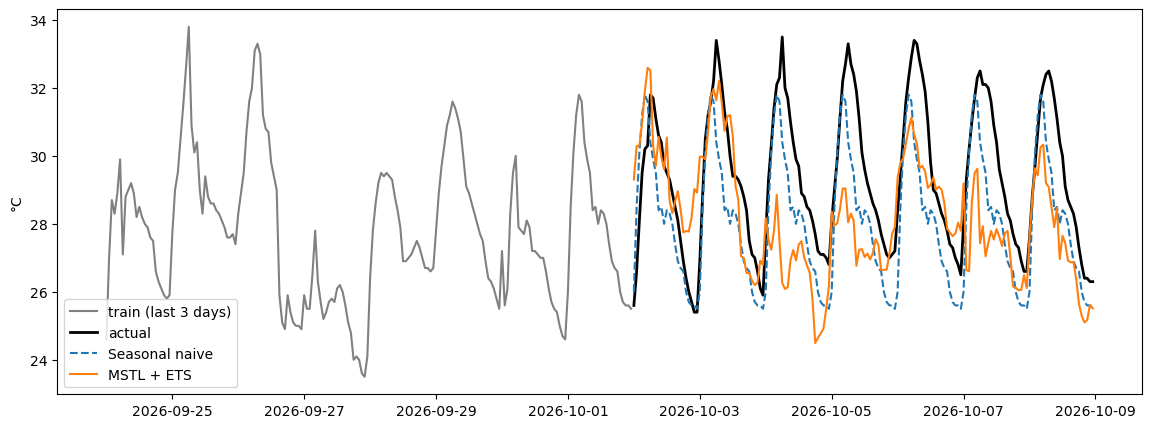

In [236]:
for name, fc in {'Seasonal naive': fc_naive, 'MSTL': fc_mstl}.items():
    print(f"{name:15s} RMSE {np.sqrt(mean_squared_error(test, fc)):.2f}  MAE {mean_absolute_error(test, fc):.2f}")

plt.figure(figsize=(14, 5))
plt.plot(train[-24*8:], color='grey', label='train (last 3 days)')
plt.plot(test, color='black', linewidth=2, label='actual')
plt.plot(test.index, fc_naive, '--', label='Seasonal naive')
plt.plot(test.index, fc_mstl, label='MSTL + ETS')
plt.legend(); plt.ylabel('°C'); plt.show()


Here, the seasonal naive forecast has lower RMSE and MAE compared to MSTL method. It performs better because the test days actually have a very similar daily pattern (shpae) to the day before of the train set. The MSTL uses a smoothed, average daily cycle so it underestimates the temperature daily swing. When the weather stays similar from day to day, copying the most recent day is a strong forecast, but would do worse if the the last training day is unusual. 

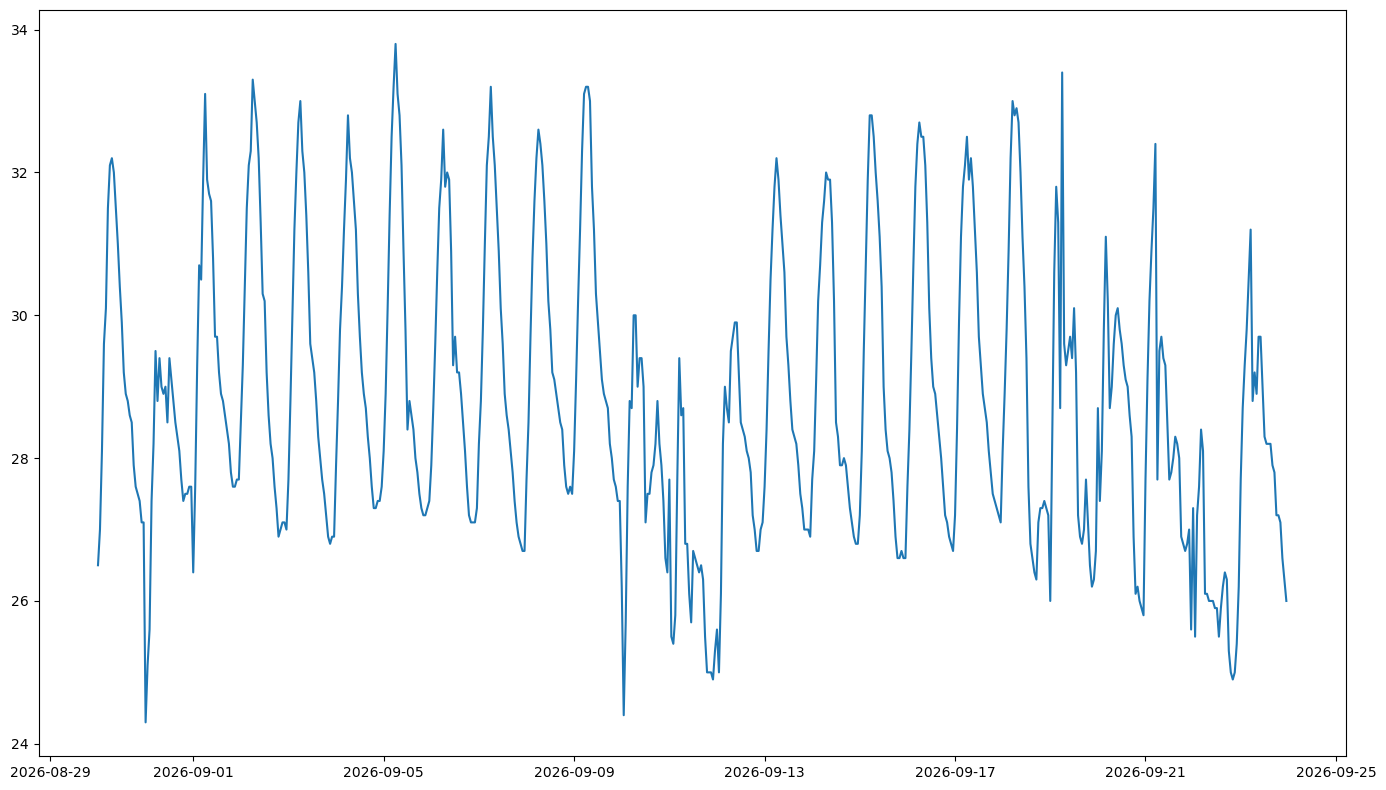

In [237]:
plt.figure(figsize=(14, 8))
plt.plot(y.iloc[-960:-24*15])
plt.tight_layout()
plt.show()

In this picture we can see that the temperature have two types of patterns, thus the performance of forecasting model is solely depending on which of these patterns we are forecasting

In [243]:
# new_y = y.iloc[-960:-24*20]
end = len(y) - 24*20                     
train, test = y.iloc[:end - idx], y.iloc[end - idx:end]



In [244]:
fc_naive = np.tile(train[-24:].values, reps=7)


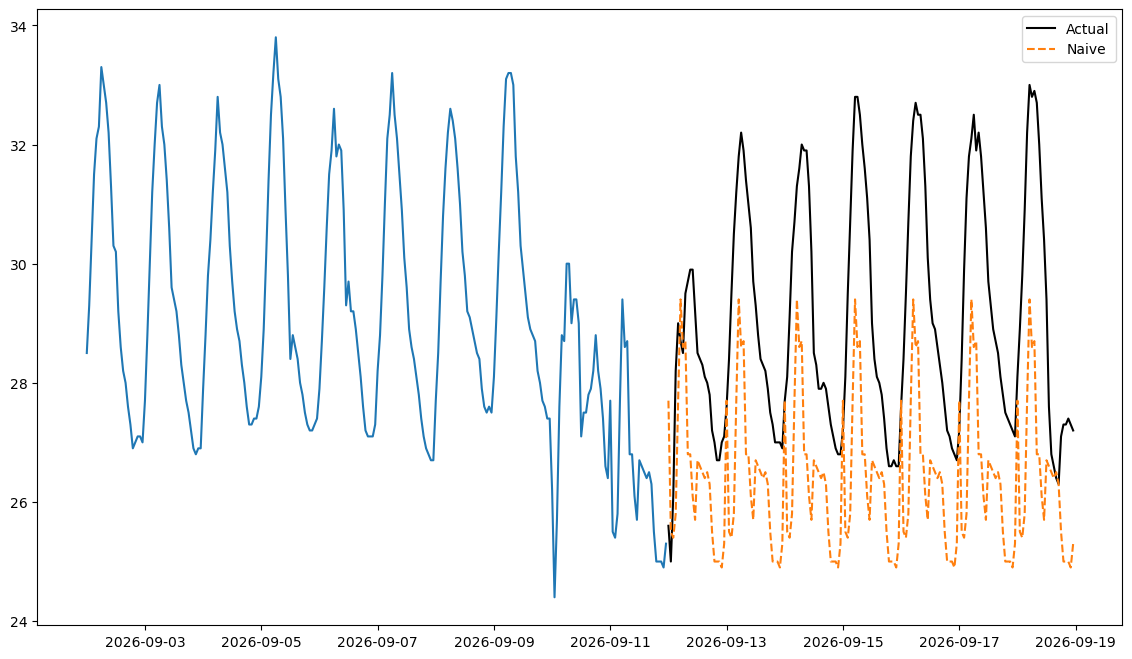

In [262]:
plt.figure(figsize=(14, 8))
plt.plot(train[-24*10:])
plt.plot(test.index, test, label='Actual', c='black')
plt.plot(test.index, fc_naive, label='Naive', linestyle='--')
plt.legend()
plt.show()

In [249]:
res_tr = MSTL(train, periods=(24, 24*365),
              stl_kwargs={'seasonal_jump': 24, 'trend_jump': 24, 'low_pass_jump': 24}).fit()
seas = res_tr.seasonal
y_adj = train - seas.sum(axis=1)
fc_adj = ExponentialSmoothing(y_adj, trend='add').fit().forecast(idx)


/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


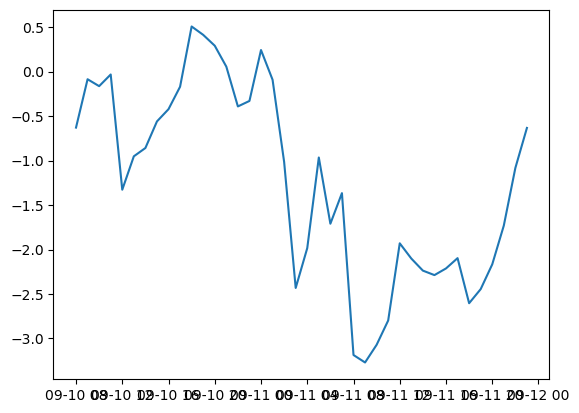

In [255]:
plt.plot(seas['seasonal_8760'][-40:])

In [257]:
daily = np.tile(seas['seasonal_24'][-24:].values, 7)
yearly = seas['seasonal_8760'][-idx:].values
fc_mstl = fc_adj + daily + yearly

Seasonal naive  RMSE 3.06  MAE 2.70
MSTL            RMSE 2.04  MAE 1.47


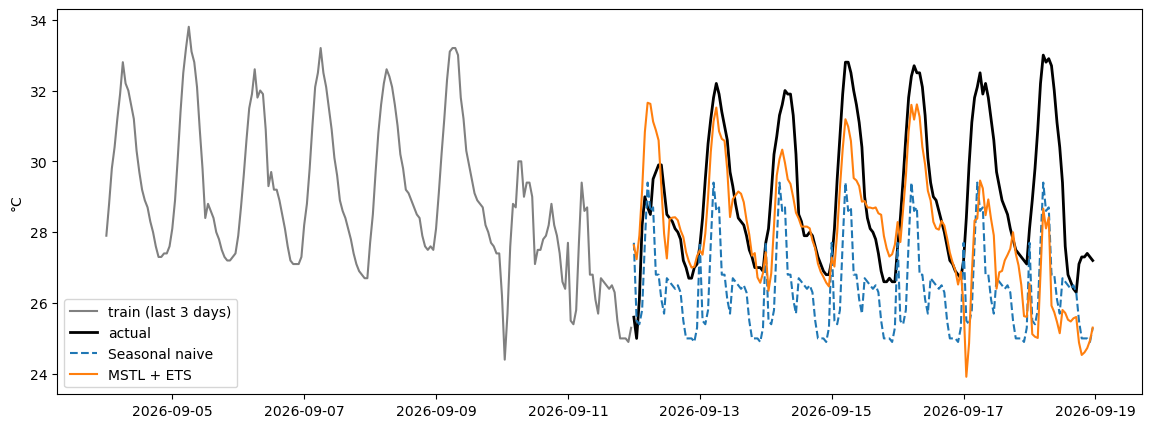

In [259]:
for name, fc in {'Seasonal naive': fc_naive, 'MSTL': fc_mstl}.items():
    print(f"{name:15s} RMSE {np.sqrt(mean_squared_error(test, fc)):.2f}  MAE {mean_absolute_error(test, fc):.2f}")

plt.figure(figsize=(14, 5))
plt.plot(train[-24*8:], color='grey', label='train (last 3 days)')
plt.plot(test, color='black', linewidth=2, label='actual')
plt.plot(test.index, fc_naive, '--', label='Seasonal naive')
plt.plot(test.index, fc_mstl, label='MSTL + ETS')
plt.legend(); 
plt.ylabel('°C'); 
plt.show()


In this example, the MSTL forecast performs better compared to naive with lower RMSE and MAE scores. This backs up our previous claim as the training data contains irregular shape unlike previous one.

f) The demand of electricity depends on the usage and human behavior. During the weekends, most businesses, schools, and buildings are closed thus demand is lower. During weekdays, most offices, schools, factories, etc are open so demand is higher. This cycle repeats weekly, 7 days, so we expect to see a peak at around 24 * 7 in the periodogram specifically. Temperature has no weekly cycle because temperatures are driven by natural Earth cycles like solar rotation rather than days of the calendar.